In [1]:
print("Hello Vephla Capstone Project")

Hello Vephla Capstone Project


In [2]:
!pip install requests beautifulsoup4 pandas matplotlib seaborn

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

print("Everything is working!")

Everything is working!


In [4]:
url = "https://books.toscrape.com/"

response = requests.get(url)

print(response.status_code)

200


In [5]:
html = response.text

print(html[:500])

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lang="en-us" class="no-js"> <!--<![endif]-->
    <head>
        <title>
    All products | Books to Scrape - Sandbox
</title>

        <meta http-equiv="content-type" content="text/html; charset=UTF-8" /


In [6]:
soup = BeautifulSoup(html, "html.parser")

print(soup.title.text.strip())

All products | Books to Scrape - Sandbox


In [7]:
books = soup.find_all("article", class_="product_pod")

print(len(books))

20


In [8]:
first_book = books[0]

print(first_book.get_text(" ", strip=True))

A Light in the ... Â£51.77 In stock Add to basket


In [9]:
title = first_book.h3.a["title"]

print(title)

A Light in the Attic


In [10]:
price = first_book.find("p", class_="price_color").text

print(price)

Â£51.77


In [11]:
rating = first_book.find("p", class_="star-rating")["class"][1]

print(rating)

Three


In [12]:
availability = first_book.find("p", class_="instock").get_text(strip=True)

print(availability)

In stock


In [13]:
book_data = {
    "title": title,
    "price": price,
    "rating": rating,
    "availability": availability
}

print(book_data)

{'title': 'A Light in the Attic', 'price': 'Â£51.77', 'rating': 'Three', 'availability': 'In stock'}


In [14]:
all_books = []

for book in books:
    title = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    rating = book.find("p", class_="star-rating")["class"][1]
    availability = book.find("p", class_="instock").get_text(strip=True)

    all_books.append({
        "title": title,
        "price": price,
        "rating": rating,
        "availability": availability
    })

print(len(all_books))

20


In [15]:
df = pd.DataFrame(all_books)

df.head()

,title,price,rating,availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [17]:
import os

print(os.getcwd())

C:\Users\HP


In [25]:
import os

for root, dirs, files in os.walk(r"C:\Users\HP"):
    if "Web_Scraping_Project" in dirs:
        print(os.path.join(root, "Web_Scraping_Project"))

C:\Users\HP\Downloads\Web_Scraping_Project


In [26]:
import os

os.chdir(r"C:\Users\HP\Downloads\Web_Scraping_Project\03_Python")

print(os.getcwd())

C:\Users\HP\Downloads\Web_Scraping_Project\03_Python


In [27]:
df.to_csv("../01_Raw_Data/books_page1_raw.csv", index=False)

print("File saved successfully!")

File saved successfully!


In [28]:

url = "https://books.toscrape.com/catalogue/page-2.html"

response = requests.get(url)

soup = BeautifulSoup(response.text, "html.parser")

books = soup.find_all("article", class_="product_pod")

print(len(books))


20


In [29]:

all_books = []

for page in range(1, 51):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")

    books = soup.find_all("article", class_="product_pod")

    for book in books:
        title = book.h3.a["title"]
        price = book.find("p", class_="price_color").text
        rating = book.find("p", class_="star-rating")["class"][1]
        availability = book.find("p", class_="instock").get_text(strip=True)

        all_books.append({
            "title": title,
            "price": price,
            "rating": rating,
            "availability": availability
        })

print("Total books collected:", len(all_books))


Total books collected: 1000


In [30]:

import pandas as pd

df = pd.DataFrame(all_books)

df.to_csv("../01_Raw_Data/books_raw.csv", index=False)

print("Full dataset saved successfully!")


Full dataset saved successfully!


In [31]:

print("Dataset shape:", df.shape)

print("\nFirst 5 books:")
display(df.head())


Dataset shape: (1000, 4)

First 5 books:


,title,price,rating,availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [32]:

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
title           0
price           0
rating          0
availability    0
dtype: int64


In [33]:

print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [34]:

print("Data types of each column:")
print(df.dtypes)


Data types of each column:
title           object
price           object
rating          object
availability    object
dtype: object


In [35]:

# Remove unwanted currency characters and convert prices to numbers
df["price"] = (
    df["price"]
    .str.replace("Â", "", regex=False)
    .str.replace("£", "", regex=False)
    .astype(float)
)

print(df[["title", "price"]].head())
print("\nPrice data type:", df["price"].dtype)


                                   title  price
0                   A Light in the Attic  51.77
1                     Tipping the Velvet  53.74
2                             Soumission  50.10
3                          Sharp Objects  47.82
4  Sapiens: A Brief History of Humankind  54.23

Price data type: float64


In [36]:

rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["rating"] = df["rating"].map(rating_mapping)

print(df[["title", "rating"]].head())

print("\nRating data type:", df["rating"].dtype)


                                   title  rating
0                   A Light in the Attic       3
1                     Tipping the Velvet       1
2                             Soumission       1
3                          Sharp Objects       4
4  Sapiens: A Brief History of Humankind       5

Rating data type: int64


In [37]:

print("Availability values:")
print(df["availability"].value_counts())


Availability values:
availability
In stock    1000
Name: count, dtype: int64


In [38]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 cleaned records:")
display(df.head())


Dataset shape: (1000, 4)

Missing values:
title           0
price           0
rating          0
availability    0
dtype: int64

Duplicate rows:
0

Data types:
title            object
price           float64
rating            int64
availability     object
dtype: object

First 5 cleaned records:


,title,price,rating,availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


In [39]:

df.to_csv("../02_Clean_Data/books_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [40]:

print("Average book price:", round(df["price"].mean(), 2))

print("Highest book price:", df["price"].max())

print("Lowest book price:", df["price"].min())


Average book price: 35.07
Highest book price: 59.99
Lowest book price: 10.0


In [41]:

print("Number of books for each rating:")
print(df["rating"].value_counts().sort_index())


Number of books for each rating:
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


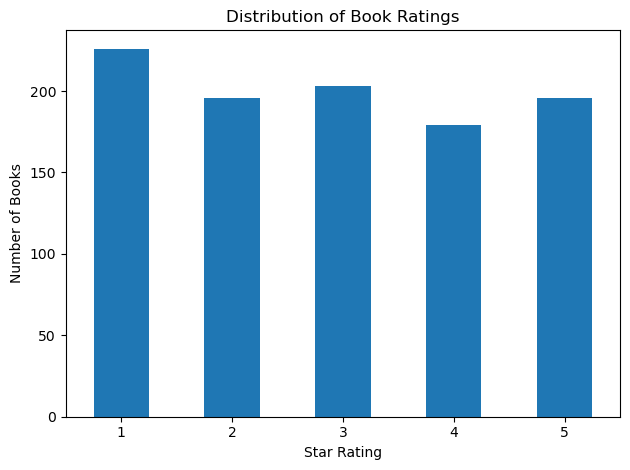

In [42]:

import matplotlib.pyplot as plt

rating_counts = df["rating"].value_counts().sort_index()

rating_counts.plot(kind="bar")

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


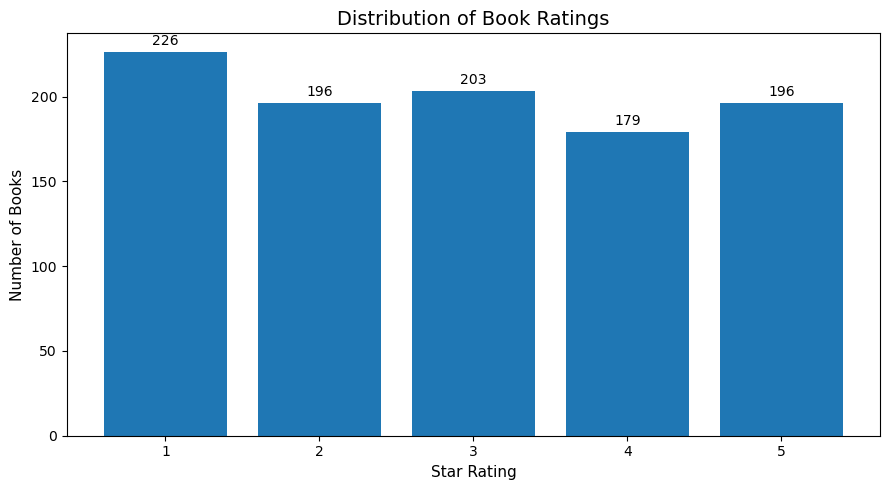

In [53]:


import matplotlib.pyplot as plt

rating_counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(rating_counts.index, rating_counts.values)

plt.title("Distribution of Book Ratings", fontsize=14)
plt.xlabel("Star Rating", fontsize=11)
plt.ylabel("Number of Books", fontsize=11)

plt.xticks([1, 2, 3, 4, 5])

plt.bar_label(bars, padding=3)

plt.tight_layout()

plt.savefig("../05_Visualizations/book_ratings.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [44]:

average_price_by_rating = df.groupby("rating")["price"].mean().round(2)

print("Average book price by rating:")
print(average_price_by_rating)


Average book price by rating:
rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: price, dtype: float64


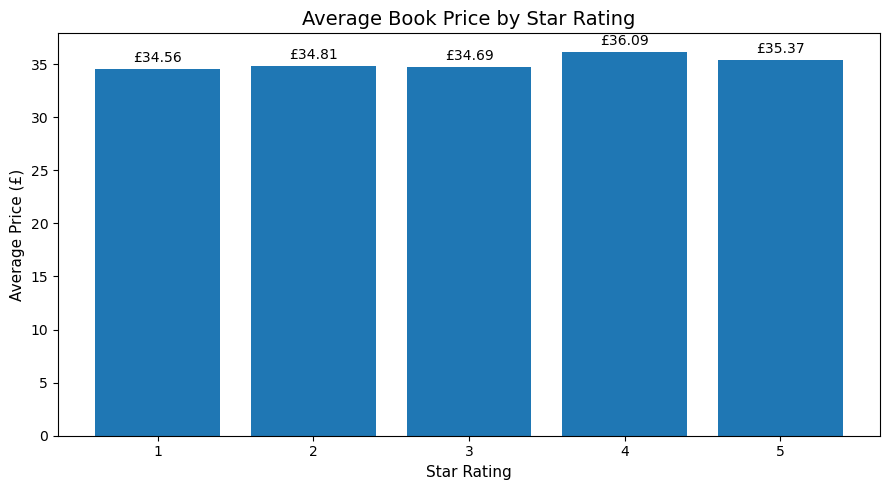

In [54]:


import matplotlib.pyplot as plt

average_price_by_rating = df.groupby("rating")["price"].mean()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    average_price_by_rating.index,
    average_price_by_rating.values
)

plt.title("Average Book Price by Star Rating", fontsize=14)
plt.xlabel("Star Rating", fontsize=11)
plt.ylabel("Average Price (£)", fontsize=11)

plt.xticks([1, 2, 3, 4, 5])
plt.bar_label(bars, fmt="£%.2f", padding=3)

plt.tight_layout()

plt.savefig("../05_Visualizations/average_price_by_rating.png",
            dpi=300, bbox_inches="tight")

plt.show()


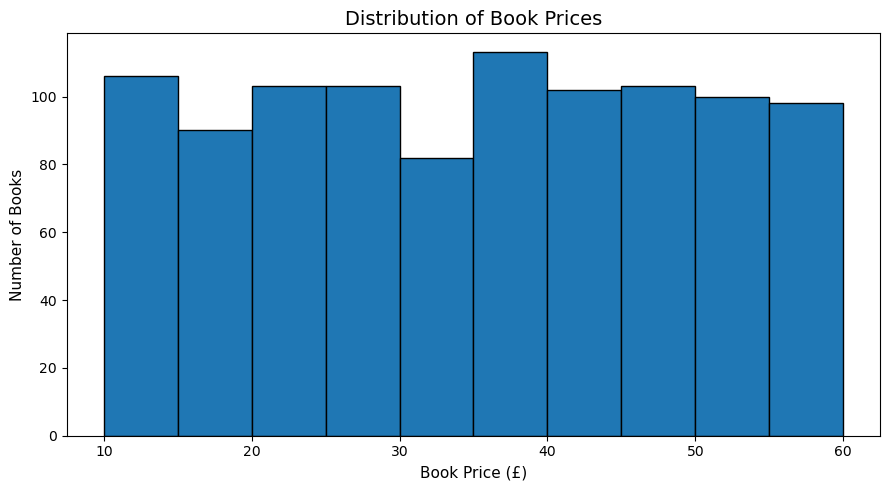

In [55]:


import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(df["price"], bins=10, edgecolor="black")

plt.title("Distribution of Book Prices", fontsize=14)
plt.xlabel("Book Price (£)", fontsize=11)
plt.ylabel("Number of Books", fontsize=11)

plt.tight_layout()

plt.savefig("../05_Visualizations/book_price_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()



In [47]:

print("10 Most Expensive Books:")
display(df.nlargest(10, "price")[["title", "price", "rating"]])

print("\n10 Cheapest Books:")
display(df.nsmallest(10, "price")[["title", "price", "rating"]])


10 Most Expensive Books:


,title,price,rating
648,The Perfect Play (Play by Play #1),59.99,3
617,Last One Home (New Beginnings #1),59.98,3
860,Civilization and Its Discontents,59.95,2
560,The Barefoot Contessa Cookbook,59.92,5
366,The Diary of a Young Girl,59.90,3
657,The Bone Hunters (Lexy Vaughan & Steven Macaul...,59.71,3
133,Thomas Jefferson and the Tripoli Pirates: The ...,59.64,1
387,Boar Island (Anna Pigeon #19),59.48,3
393,The Improbability of Love,59.45,1
549,The Man Who Mistook His Wife for a Hat and Oth...,59.45,4



10 Cheapest Books:


,title,price,rating
638,An Abundance of Katherines,10.00,5
501,The Origin of Species,10.01,4
716,The Tipping Point: How Little Things Can Make ...,10.02,2
84,Patience,10.16,3
302,Greek Mythic History,10.23,5
558,The Fellowship of the Ring (The Lord of the Ri...,10.27,2
479,History of Beauty,10.29,4
242,The Lucifer Effect: Understanding How Good Peo...,10.40,1
434,"NaNo What Now? Finding your editing process, r...",10.41,4
274,Pet Sematary,10.56,3


In [48]:

average_rating = df["rating"].mean()

print("Average book rating:", round(average_rating, 2), "out of 5")


Average book rating: 2.92 out of 5


In [49]:

print("Median book rating:", df["rating"].median())

print("Most common rating:", df["rating"].mode()[0])

print("Median book price:", round(df["price"].median(), 2))


Median book rating: 3.0
Most common rating: 1
Median book price: 35.98


In [50]:

print("BOOK DATASET - KEY FINDINGS")
print("----------------------------")
print("Total books:", len(df))
print("Average price: £", round(df["price"].mean(), 2))
print("Highest price: £", df["price"].max())
print("Lowest price: £", df["price"].min())
print("Average rating:", round(df["rating"].mean(), 2), "/ 5")
print("Median rating:", df["rating"].median())
print("Most common rating:", df["rating"].mode()[0])
print("Median price: £", round(df["price"].median(), 2))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


BOOK DATASET - KEY FINDINGS
----------------------------
Total books: 1000
Average price: £ 35.07
Highest price: £ 59.99
Lowest price: £ 10.0
Average rating: 2.92 / 5
Median rating: 3.0
Most common rating: 1
Median price: £ 35.98
Missing values: 0
Duplicate rows: 0


In [51]:

print("PRICE SUMMARY")
print(df["price"].describe().round(2))


PRICE SUMMARY
count    1000.00
mean       35.07
std        14.45
min        10.00
25%        22.11
50%        35.98
75%        47.46
max        59.99
Name: price, dtype: float64


In [52]:
print("PRICE ANALYSIS")
print("--------------")
print("The dataset contains 1,000 books.")
print("The average book price is £35.07.")
print("The cheapest book costs £10.00.")
print("The most expensive book costs £59.99.")
print("The median book price is £35.98.")
print("The middle 50% of book prices range from £22.11 to £47.46.")

PRICE ANALYSIS
--------------
The dataset contains 1,000 books.
The average book price is £35.07.
The cheapest book costs £10.00.
The most expensive book costs £59.99.
The median book price is £35.98.
The middle 50% of book prices range from £22.11 to £47.46.


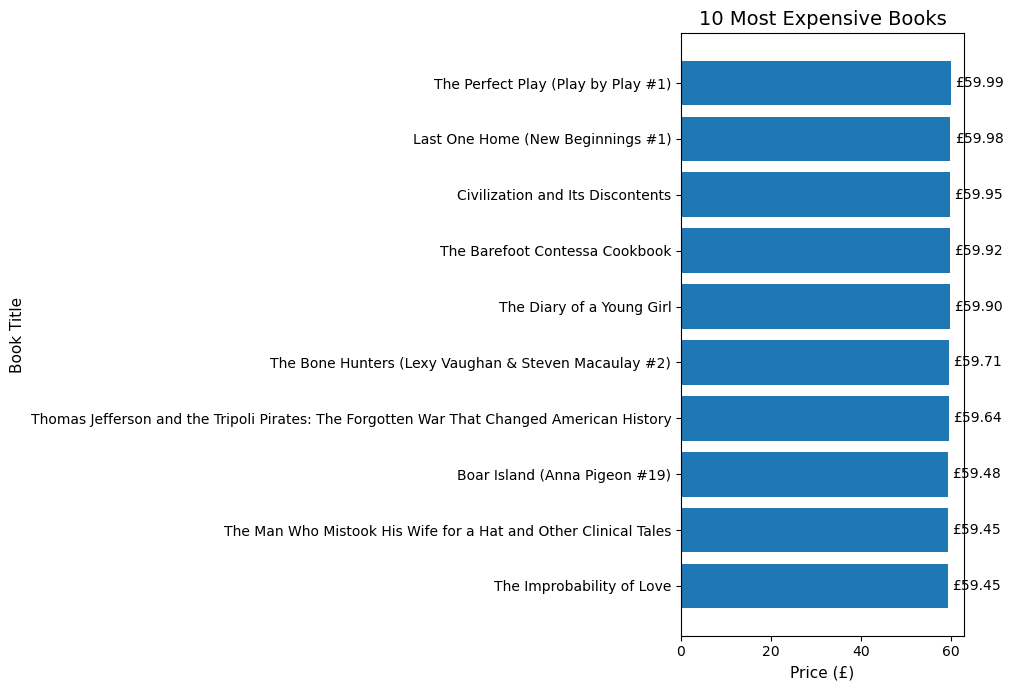

In [56]:

import matplotlib.pyplot as plt

top_10_expensive = df.nlargest(10, "price").sort_values("price")

plt.figure(figsize=(10, 7))

bars = plt.barh(
    top_10_expensive["title"],
    top_10_expensive["price"]
)

plt.title("10 Most Expensive Books", fontsize=14)
plt.xlabel("Price (£)", fontsize=11)
plt.ylabel("Book Title", fontsize=11)

plt.bar_label(bars, fmt="£%.2f", padding=3)
plt.tight_layout()

plt.savefig("../05_Visualizations/top_10_expensive_books.png",
            dpi=300, bbox_inches="tight")

plt.show()


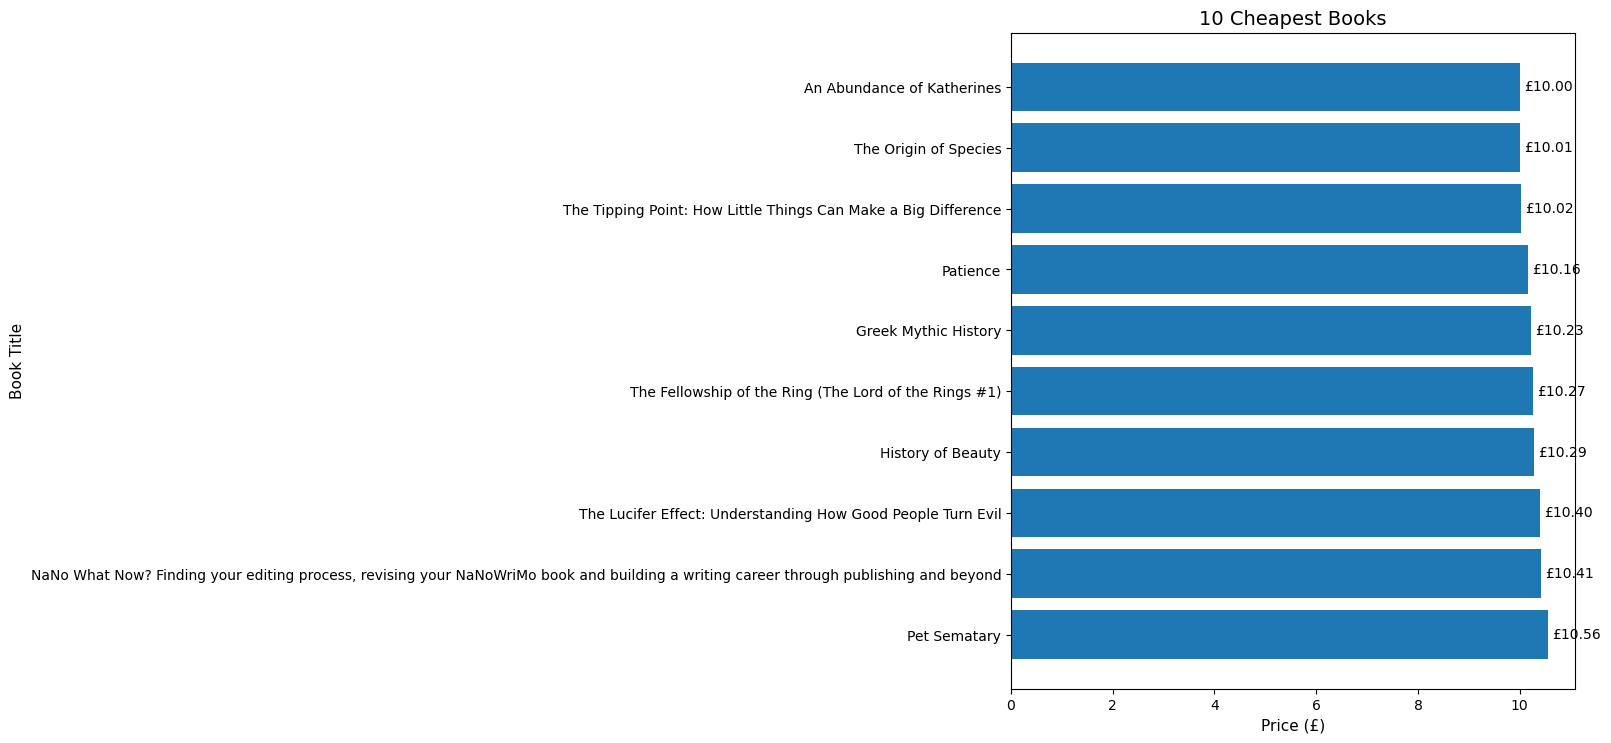

In [58]:


import matplotlib.pyplot as plt

top_10_cheapest = df.nsmallest(10, "price").sort_values("price", ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    top_10_cheapest["title"],
    top_10_cheapest["price"]
)

ax.set_title("10 Cheapest Books", fontsize=14)
ax.set_xlabel("Price (£)", fontsize=11)
ax.set_ylabel("Book Title", fontsize=11)

ax.bar_label(bars, fmt="£%.2f", padding=3)
fig.subplots_adjust(left=0.45, right=0.92, top=0.92, bottom=0.10)

plt.savefig(
    "../05_Visualizations/top_10_cheapest_books.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [59]:

import requests
import pandas as pd
import time
from bs4 import BeautifulSoup
from urllib.parse import urljoin

base_url = "https://books.toscrape.com/"
all_categories = []

for page in range(1, 51):
    listing_url = f"{base_url}catalogue/page-{page}.html"
    response = requests.get(listing_url, timeout=20)
    soup = BeautifulSoup(response.text, "html.parser")

    books = soup.find_all("article", class_="product_pod")

    for book in books:
        title = book.h3.a["title"]
        book_url = urljoin(listing_url, book.h3.a["href"])

        try:
            book_response = requests.get(book_url, timeout=20)
            book_soup = BeautifulSoup(
                book_response.text, "html.parser"
            )

            breadcrumb_links = book_soup.select(
                "ul.breadcrumb li a"
            )

            if book_response.status_code == 200 and len(breadcrumb_links) >= 3:
                category = breadcrumb_links[2].get_text(strip=True)
            else:
                category = "Unknown"

        except requests.RequestException:
            category = "Unknown"

        all_categories.append({
            "title": title,
            "category": category
        })

        time.sleep(0.1)

    print(f"Finished listing page {page} of 50")

category_df = pd.DataFrame(all_categories)

print("\nTotal books processed:", len(category_df))
print("\nCategory counts:")
print(category_df["category"].value_counts())


Finished listing page 1 of 50
Finished listing page 2 of 50
Finished listing page 3 of 50
Finished listing page 4 of 50
Finished listing page 5 of 50
Finished listing page 6 of 50
Finished listing page 7 of 50
Finished listing page 8 of 50
Finished listing page 9 of 50
Finished listing page 10 of 50
Finished listing page 11 of 50
Finished listing page 12 of 50
Finished listing page 13 of 50
Finished listing page 14 of 50
Finished listing page 15 of 50
Finished listing page 16 of 50
Finished listing page 17 of 50
Finished listing page 18 of 50
Finished listing page 19 of 50
Finished listing page 20 of 50
Finished listing page 21 of 50
Finished listing page 22 of 50
Finished listing page 23 of 50
Finished listing page 24 of 50
Finished listing page 25 of 50
Finished listing page 26 of 50
Finished listing page 27 of 50
Finished listing page 28 of 50
Finished listing page 29 of 50
Finished listing page 30 of 50
Finished listing page 31 of 50
Finished listing page 32 of 50
Finished listing 

In [60]:

# Check the category data we collected

print("Total category records:", len(category_df))
print("Unique book titles:", category_df["title"].nunique())

print("\nBooks with Default category:")
print(category_df[category_df["category"] == "Default"].head(10))

print("\nBooks with Add a comment category:")
print(category_df[category_df["category"] == "Add a comment"].head(10))

print("\nBooks with Unknown category:")
print(category_df[category_df["category"] == "Unknown"].head(10))


Total category records: 1000
Unique book titles: 999

Books with Default category:
                                                 title category
7    The Coming Woman: A Novel Based on the Life of...  Default
8    The Boys in the Boat: Nine Americans and Their...  Default
10      Starving Hearts (Triangular Trade Trilogy, #1)  Default
26   America's Cradle of Quarterbacks: Western Penn...  Default
27                      Aladdin and His Wonderful Lamp  Default
35                                         Penny Maybe  Default
36      Maude (1883-1993):She Grew Up with the country  Default
65   The Inefficiency Assassin: Time Management Tac...  Default
74                                         Soul Reader  Default
117                                         Bossypants  Default

Books with Add a comment category:
                                                 title       category
55         The Torch Is Passed: A Harding Family Story  Add a comment
63   The Mindfulness and Acceptance W

In [61]:

# Find titles that appear more than once

duplicate_titles = category_df[
    category_df["title"].duplicated(keep=False)
].sort_values("title")

print("Duplicate title records:")
print(duplicate_titles.to_string(index=False))


Duplicate title records:
                 title category
The Star-Touched Queen  Fantasy
The Star-Touched Queen  Fantasy


In [62]:

import requests
from bs4 import BeautifulSoup

test_url = "https://books.toscrape.com/catalogue/the-coming-woman-a-novel-based-on-the-life-of-the-infamous-feminist-victoria-woodhull_993/index.html"

response = requests.get(test_url, timeout=20)
soup = BeautifulSoup(response.text, "html.parser")

print("Status code:", response.status_code)
print("\nBreadcrumb links:")

for link in soup.select("ul.breadcrumb li a"):
    print(repr(link.get_text(strip=True)), "->", link.get("href"))


Status code: 200

Breadcrumb links:
'Home' -> ../../index.html
'Books' -> ../category/books_1/index.html
'Default' -> ../category/books/default_15/index.html


In [63]:

# Inspect the category link for one book

category_link = soup.select_one(
    "ul.breadcrumb li:nth-of-type(3) a"
)

if category_link:
    print("Category text:", category_link.get_text(strip=True))
    print("Category URL:", category_link.get("href"))
else:
    print("No category link found.")


Category text: Default
Category URL: ../category/books/default_15/index.html


In [65]:

import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import time

base_url = "https://books.toscrape.com/"
session = requests.Session()

book_links = []
corrected_categories = []

# Read the 50 catalogue pages only once
for page in range(1, 51):
    listing_url = f"{base_url}catalogue/page-{page}.html"
    response = session.get(listing_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    for book in soup.select("article.product_pod"):
        book_links.append({
            "title": book.h3.a["title"],
            "url": urljoin(listing_url, book.h3.a["href"])
        })

    print(f"Catalogue page {page} of 50 collected")

# Remove duplicate titles from the category lookup
books_df = pd.DataFrame(book_links).drop_duplicates(
    subset="title",
    keep="first"
)

# Visit each book page to retrieve its category
for index, book in enumerate(books_df.to_dict("records"), start=1):
    category = "Unknown"

    try:
        response = session.get(book["url"], timeout=20)
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")
        breadcrumb_links = soup.select("ul.breadcrumb li a")

        if len(breadcrumb_links) >= 3:
            category = breadcrumb_links[2].get_text(strip=True)

    except requests.RequestException:
        pass

    corrected_categories.append({
        "title": book["title"],
        "category": category
    })

    if index % 100 == 0:
        print(f"Book details checked: {index} of {len(books_df)}")

    time.sleep(0.1)

corrected_category_df = pd.DataFrame(corrected_categories)

print("\nUnique titles checked:", len(corrected_category_df))
print("\nCategory counts:")
print(corrected_category_df["category"].value_counts())


Catalogue page 1 of 50 collected
Catalogue page 2 of 50 collected
Catalogue page 3 of 50 collected
Catalogue page 4 of 50 collected
Catalogue page 5 of 50 collected
Catalogue page 6 of 50 collected
Catalogue page 7 of 50 collected
Catalogue page 8 of 50 collected
Catalogue page 9 of 50 collected
Catalogue page 10 of 50 collected
Catalogue page 11 of 50 collected
Catalogue page 12 of 50 collected
Catalogue page 13 of 50 collected
Catalogue page 14 of 50 collected
Catalogue page 15 of 50 collected
Catalogue page 16 of 50 collected
Catalogue page 17 of 50 collected
Catalogue page 18 of 50 collected
Catalogue page 19 of 50 collected
Catalogue page 20 of 50 collected
Catalogue page 21 of 50 collected
Catalogue page 22 of 50 collected
Catalogue page 23 of 50 collected
Catalogue page 24 of 50 collected
Catalogue page 25 of 50 collected
Catalogue page 26 of 50 collected
Catalogue page 27 of 50 collected
Catalogue page 28 of 50 collected
Catalogue page 29 of 50 collected
Catalogue page 30 of 50

In [67]:

# Inspect the collected category data without internet access

print("Total category records:", len(corrected_category_df))

print("\nBooks labelled 'Add a comment':")
print(
    corrected_category_df.loc[
        corrected_category_df["category"] == "Add a comment",
        ["title", "category"]
    ].head(10).to_string(index=False)
)

print("\nBooks labelled 'Default':")
print(
    corrected_category_df.loc[
        corrected_category_df["category"] == "Default",
        ["title", "category"]
    ].head(10).to_string(index=False)
)

print("\nBooks labelled 'Unknown':")
print(
    corrected_category_df.loc[
        corrected_category_df["category"] == "Unknown",
        ["title", "category"]
    ].to_string(index=False)
)


Total category records: 999

Books labelled 'Add a comment':
                                                                                                                                                 title      category
                                                                                                           The Torch Is Passed: A Harding Family Story Add a comment
The Mindfulness and Acceptance Workbook for Anxiety: A Guide to Breaking Free from Anxiety, Phobias, and Worry Using Acceptance and Commitment Therapy Add a comment
                                                                                                                                        The Art Forger Add a comment
                                                                                                                                   On a Midnight Clear Add a comment
                                                                                 Judo: Seven Steps to Black Belt (

In [68]:

# Prepare the category data for merging

category_lookup = corrected_category_df.copy()

# Check that each title appears only once in the category lookup
print("Category lookup rows:", len(category_lookup))
print("Unique category lookup titles:", category_lookup["title"].nunique())

# Treat "Add a comment" as a missing category, not a real category
category_lookup["category"] = category_lookup["category"].replace(
    "Add a comment", pd.NA
)

# Merge categories into the original cleaned dataset
df_enriched = df.merge(
    category_lookup[["title", "category"]],
    on="title",
    how="left",
    validate="many_to_one"
)

# Check the results
print("\nOriginal cleaned dataset rows:", len(df))
print("Enriched dataset rows:", len(df_enriched))
print("Missing categories:", df_enriched["category"].isna().sum())

print("\nFirst five rows:")
print(df_enriched.head())

# Save a separate review copy; do not overwrite the original yet
df_enriched.to_csv(
    "../02_Clean_Data/books_cleaned_with_categories_review.csv",
    index=False
)

print("\nReview copy saved successfully.")


Category lookup rows: 999
Unique category lookup titles: 999

Original cleaned dataset rows: 1000
Enriched dataset rows: 1000
Missing categories: 67

First five rows:
                                   title  price  rating availability  \
0                   A Light in the Attic  51.77       3     In stock   
1                     Tipping the Velvet  53.74       1     In stock   
2                             Soumission  50.10       1     In stock   
3                          Sharp Objects  47.82       4     In stock   
4  Sapiens: A Brief History of Humankind  54.23       5     In stock   

             category  
0              Poetry  
1  Historical Fiction  
2             Fiction  
3             Mystery  
4             History  

Review copy saved successfully.


In [69]:

print("Original dataset rows:", len(df))
print("Enriched dataset rows:", len(df_enriched))

print("\nDataset columns:")
print(df_enriched.columns.tolist())

print("\nMissing values per column:")
print(df_enriched.isna().sum())

print("\nNumber of unique categories:")
print(df_enriched["category"].nunique())

print("\nTop 10 categories:")
print(df_enriched["category"].value_counts().head(10))


Original dataset rows: 1000
Enriched dataset rows: 1000

Dataset columns:
['title', 'price', 'rating', 'availability', 'category']

Missing values per column:
title            0
price            0
rating           0
availability     0
category        67
dtype: int64

Number of unique categories:
49

Top 10 categories:
category
Default           152
Nonfiction        110
Sequential Art     75
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Childrens          29
Name: count, dtype: int64


In [70]:

# EXPLORATORY DATA ANALYSIS

# 1. Summary statistics
print("PRICE SUMMARY")
print(df_enriched["price"].describe().round(2))

print("\nRATING SUMMARY")
print(df_enriched["rating"].describe().round(2))

# 2. Correlation between numeric variables
print("\nCORRELATION MATRIX")
print(
    df_enriched[["price", "rating"]]
    .corr()
    .round(3)
)

# 3. Average price and rating by category
category_summary = (
    df_enriched.dropna(subset=["category"])
    .groupby("category")
    .agg(
        book_count=("title", "count"),
        average_price=("price", "mean"),
        average_rating=("rating", "mean")
    )
    .round(2)
    .sort_values("book_count", ascending=False)
)

print("\nTOP 10 CATEGORIES BY BOOK COUNT")
print(category_summary.head(10))

# 4. Outlier check using the IQR method
q1 = df_enriched["price"].quantile(0.25)
q3 = df_enriched["price"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

price_outliers = df_enriched[
    (df_enriched["price"] < lower_bound) |
    (df_enriched["price"] > upper_bound)
]

print("\nPRICE OUTLIER CHECK")
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Number of potential price outliers:", len(price_outliers))

print("\nMost expensive potential outliers:")
print(
    price_outliers[["title", "price", "rating", "category"]]
    .sort_values("price", ascending=False)
    .head(10)
    .to_string(index=False)
)


PRICE SUMMARY
count    1000.00
mean       35.07
std        14.45
min        10.00
25%        22.11
50%        35.98
75%        47.46
max        59.99
Name: price, dtype: float64

RATING SUMMARY
count    1000.00
mean        2.92
std         1.43
min         1.00
25%         2.00
50%         3.00
75%         4.00
max         5.00
Name: rating, dtype: float64

CORRELATION MATRIX
        price  rating
price   1.000   0.028
rating  0.028   1.000

TOP 10 CATEGORIES BY BOOK COUNT
                book_count  average_price  average_rating
category                                                 
Default                152          34.39            2.84
Nonfiction             110          34.26            2.88
Sequential Art          75          34.57            2.97
Fiction                 65          36.07            3.18
Young Adult             54          35.45            3.30
Fantasy                 48          39.59            3.08
Romance                 35          33.93            2.63


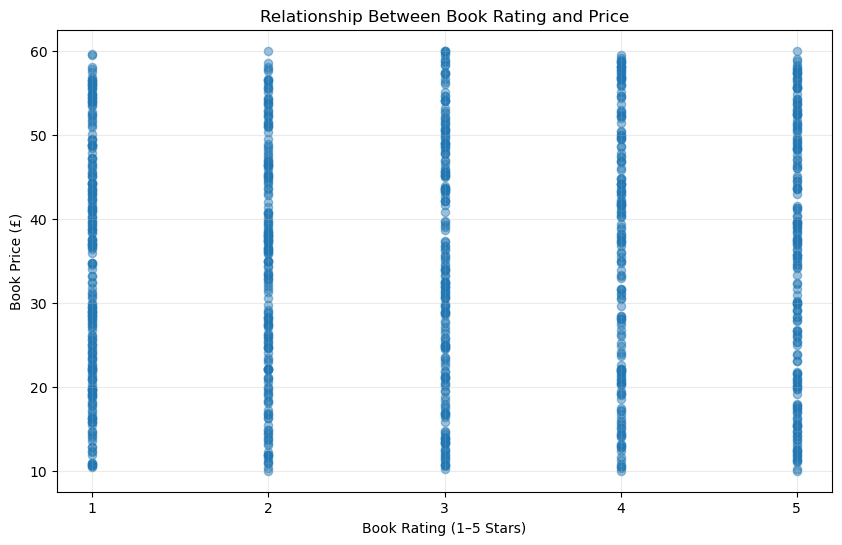

In [71]:

import matplotlib.pyplot as plt

# Scatter plot: book price versus rating
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    df_enriched["rating"],
    df_enriched["price"],
    alpha=0.45,
    s=35
)

ax.set_title("Relationship Between Book Rating and Price")
ax.set_xlabel("Book Rating (1–5 Stars)")
ax.set_ylabel("Book Price (£)")
ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(True, alpha=0.25)

plt.savefig(
    "../05_Visualizations/price_vs_rating_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


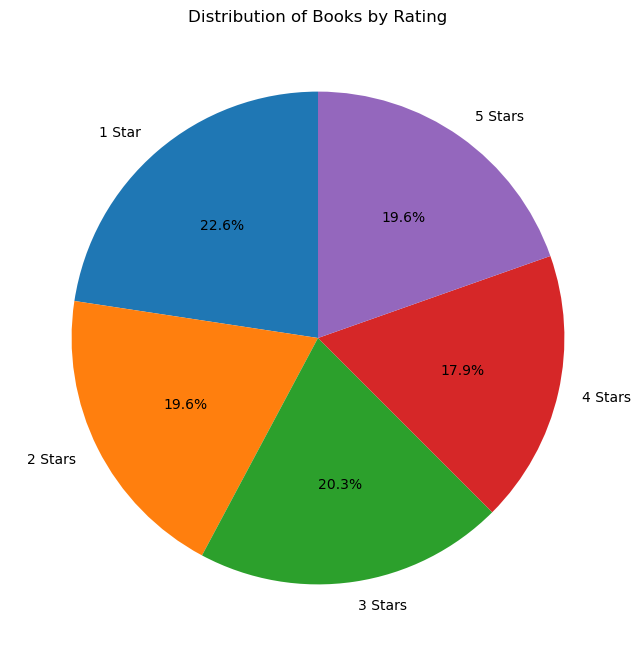

In [72]:

import matplotlib.pyplot as plt

# Count books at each rating level
rating_counts = (
    df_enriched["rating"]
    .value_counts()
    .sort_index()
)

rating_labels = [
    f"{rating} Star" if rating == 1 else f"{rating} Stars"
    for rating in rating_counts.index
]

fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    rating_counts,
    labels=rating_labels,
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Distribution of Books by Rating")

plt.savefig(
    "../05_Visualizations/book_rating_pie_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


1-star books: 226
2-star books: 196
3-star books: 203
4-star books: 179
5-star books: 196


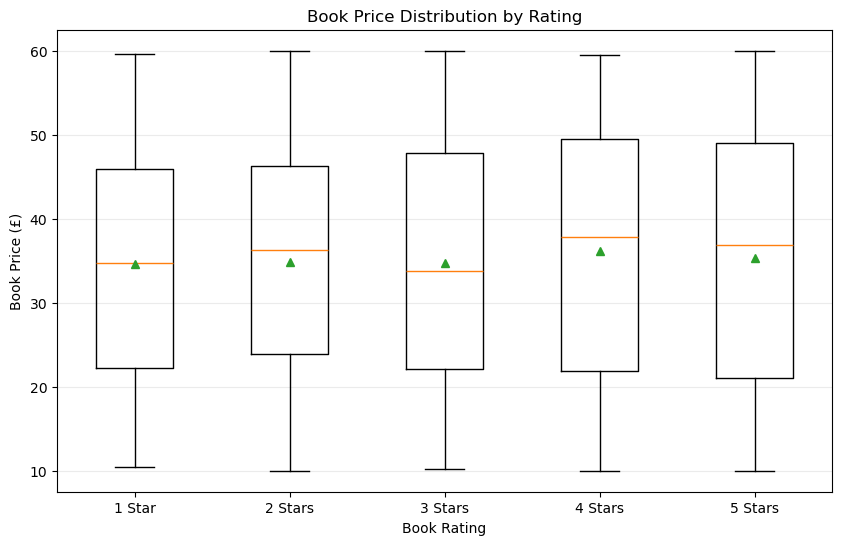

In [74]:


import matplotlib.pyplot as plt

# Prepare prices for each rating
ratings = [1, 2, 3, 4, 5]

price_by_rating = [
    df_enriched.loc[df_enriched["rating"] == r, "price"].dropna()
    for r in ratings
]

# Confirm that each rating group contains data
for r, prices in zip(ratings, price_by_rating):
    print(f"{r}-star books: {len(prices)}")

# Create the box plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    price_by_rating,
    labels=["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"],
    showmeans=True
)

ax.set_title("Book Price Distribution by Rating")
ax.set_xlabel("Book Rating")
ax.set_ylabel("Book Price (£)")
ax.grid(axis="y", alpha=0.25)

fig.savefig(
    "../05_Visualizations/book_price_boxplot_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


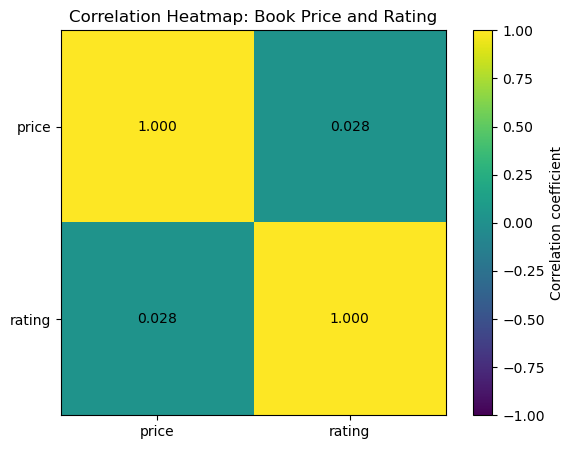

In [75]:

import matplotlib.pyplot as plt
import pandas as pd

# Calculate correlations between numeric columns
correlation_matrix = df_enriched[["price", "rating"]].corr()

fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(correlation_matrix, vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(correlation_matrix.columns)
ax.set_yticklabels(correlation_matrix.columns)

# Display correlation values inside the heatmap
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

ax.set_title("Correlation Heatmap: Book Price and Rating")
fig.colorbar(image, ax=ax, label="Correlation coefficient")

plt.savefig(
    "../05_Visualizations/book_price_rating_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


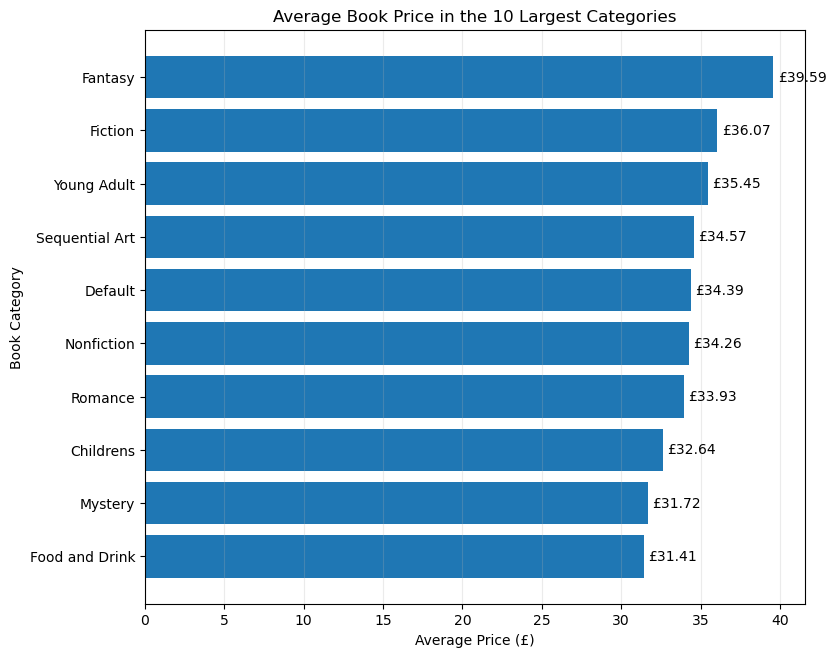

In [76]:

import matplotlib.pyplot as plt

# Calculate average price for the 10 largest categories
top_categories = (
    df_enriched.dropna(subset=["category"])
    .groupby("category")
    .agg(
        book_count=("title", "count"),
        average_price=("price", "mean")
    )
    .sort_values("book_count", ascending=False)
    .head(10)
    .sort_values("average_price", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_categories.index,
    top_categories["average_price"]
)

ax.set_title("Average Book Price in the 10 Largest Categories")
ax.set_xlabel("Average Price (£)")
ax.set_ylabel("Book Category")

ax.bar_label(bars, fmt="£%.2f", padding=3)
ax.grid(axis="x", alpha=0.25)

fig.subplots_adjust(left=0.30, right=0.90, top=0.92, bottom=0.10)

plt.savefig(
    "../05_Visualizations/average_price_top_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [77]:

# Final dataset quality checks

print("Dataset shape:", df_enriched.shape)
print("\nDuplicate rows:", df_enriched.duplicated().sum())
print("\nMissing values by column:")
print(df_enriched.isna().sum())

# Save the enriched cleaned dataset
df_enriched.to_csv(
    "../02_Clean_Data/books_cleaned.csv",
    index=False
)

print("\nFinal cleaned dataset saved successfully.")


Dataset shape: (1000, 5)

Duplicate rows: 0

Missing values by column:
title            0
price            0
rating           0
availability     0
category        67
dtype: int64

Final cleaned dataset saved successfully.


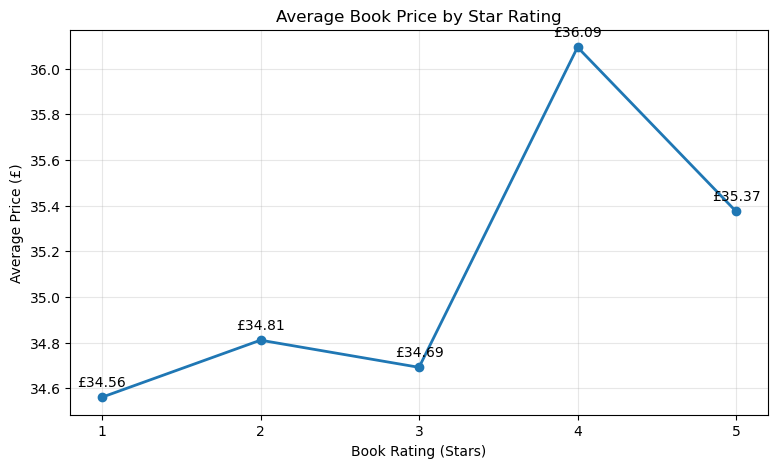

In [78]:

import matplotlib.pyplot as plt

# Calculate the average price for each star rating
average_price_rating = (
    df_enriched.groupby("rating")["price"].mean()
)

# Create the line chart
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    average_price_rating.index,
    average_price_rating.values,
    marker="o",
    linewidth=2
)

ax.set_title("Average Book Price by Star Rating")
ax.set_xlabel("Book Rating (Stars)")
ax.set_ylabel("Average Price (£)")
ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(True, alpha=0.3)

# Display the price beside each point
for x, y in zip(
    average_price_rating.index,
    average_price_rating.values
):
    ax.annotate(
        f"£{y:.2f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

# Save the chart
plt.savefig(
    "../05_Visualizations/average_price_line_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
